# PASE ORACLE ES_01 OF LAB_02

## Qiskit implementation ob phase oracles

In [23]:
%pip install matplotlib pylatexenc
from qiskit import QuantumCircuit
from qiskit import transpile
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.visualization import plot_histogram

Note: you may need to restart the kernel to use updated packages.


Oracle $| \11 \rangle$

In [17]:

qc_11 = QuantumCircuit(2,2)

# Qubit initialization
qc_11.h(0)
qc_11.h(1)

# Phase oracle makeing $| \11 \rangle$
qc_11.cz(0,1)

# Diffuser
qc_11.h(0)
qc_11.h(1)
qc_11.x(0)
qc_11.x(1)
qc_11.cz(0,1)
qc_11.x(0)
qc_11.x(1)
qc_11.h(0)
qc_11.h(1)

print(qc_11.draw("text"))

     ┌───┐   ┌───┐┌───┐   ┌───┐┌───┐
q_0: ┤ H ├─■─┤ H ├┤ X ├─■─┤ X ├┤ H ├
     ├───┤ │ ├───┤├───┤ │ ├───┤├───┤
q_1: ┤ H ├─■─┤ H ├┤ X ├─■─┤ X ├┤ H ├
     └───┘   └───┘└───┘   └───┘└───┘
c: 2/═══════════════════════════════
                                    


Oracle $| \10 \rangle$ .
Remember that in qiskit the bitsctring is visualized $| \q_1 \q_0 \rangle$

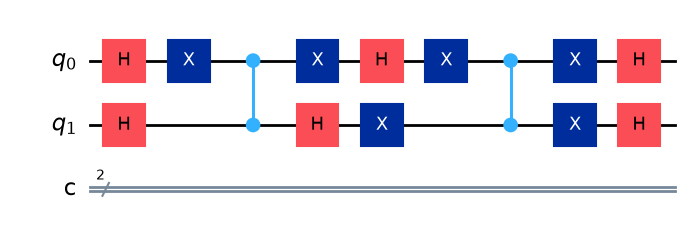

In [41]:
qc_10 = QuantumCircuit(2,2)

# Qubit initialization
qc_10.h(0)
qc_10.h(1)

# Phase oracle makeing $| \10 \rangle$
qc_10.x(0)
qc_10.cz(0,1)
qc_10.x(0)

# Diffuser
qc_10.h(0)
qc_10.h(1)
qc_10.x(0)
qc_10.x(1)
qc_10.cz(0,1)
qc_10.x(0)
qc_10.x(1)
qc_10.h(0)
qc_10.h(1)

display(qc_10.draw("mpl"))

Oracle $| \01 \rangle$ .

In [ ]:
qc_01 = QuantumCircuit(2,2)

# Qubit initialization
qc_01.h(0)
qc_01.h(1)

#Phase oracle makeing $| \01 \rangle$
qc_01.x(1)
qc_01.cz(0,1)
qc_01.x(1)

# Diffuser
qc_01.h(0)
qc_01.h(1)
qc_01.x(0)
qc_01.x(1)
qc_01.cz(0,1)
qc_01.x(0)
qc_01.x(1)
qc_01.h(0)
qc_01.h(1)

print(qc_01.draw("text"))


     ┌───┐             
q_0: ┤ H ├──────■──────
     ├───┤┌───┐ │ ┌───┐
q_1: ┤ H ├┤ X ├─■─┤ X ├
     └───┘└───┘   └───┘
c: 2/══════════════════
                       


Oracle $| \00 \rangle$ .

In [19]:
qc_00= QuantumCircuit(2,2)

# Qubit initialization
qc_00.h(0)
qc_00.h(1)

#Phase oracle makeing $| \00 \rangle$
qc_00.x(1)
qc_00.cz(0,1, ctrl_state=0)
qc_00.x(1)

# Diffuser
qc_00.h(0)
qc_00.h(1)
qc_00.x(0)
qc_00.x(1)
qc_00.cz(0,1)
qc_00.x(0)
qc_00.x(1)
qc_00.h(0)
qc_00.h(1)

print(qc_00.draw("text"))

     ┌───┐        ┌───┐┌───┐        ┌───┐┌───┐
q_0: ┤ H ├──────o─┤ H ├┤ X ├──────■─┤ X ├┤ H ├
     ├───┤┌───┐ │ ├───┤├───┤┌───┐ │ ├───┤├───┤
q_1: ┤ H ├┤ X ├─■─┤ X ├┤ H ├┤ X ├─■─┤ X ├┤ H ├
     └───┘└───┘   └───┘└───┘└───┘   └───┘└───┘
c: 2/═════════════════════════════════════════
                                              


## Phase oracle function
Function that generate autamtically the phase oracle

In [ ]:
def phase_oracle(marked_state: str) -> QuantumCircuit:
    oracle = QuantumCircuit(2, name=f"0_{marked_state}")
    for qubit, bit in enumerate(reversed(marked_state)):
        if bit == "0":
            oracle.x(qubit)

    # Apply phase shift
    oracle.cz(0,1)

    # Uncomputation
    for qubit, bit in enumerate(reversed(marked_state)):
        if bit == "0":
            oracle.x(qubit)

    return oracle

def diffuser() -> QuantumCircuit:
    diff = QuantumCircuit(2, name="Diffuser")

    diff.h([0, 1])
    diff.x([0, 1])
    diff.cz(0, 1)
    diff.x([0, 1])
    diff.h([0, 1])

    return diff 



In [12]:
for state in ["00", "01", "10", "11"]:
    oracle = phase_oracle(state)
    print(f"\nOracle for |{state}>:")
    print(oracle.draw("text"))


Oracle for |00>:
     ┌───┐   ┌───┐
q_0: ┤ X ├─■─┤ X ├
     ├───┤ │ ├───┤
q_1: ┤ X ├─■─┤ X ├
     └───┘   └───┘

Oracle for |01>:
                  
q_0: ──────■──────
     ┌───┐ │ ┌───┐
q_1: ┤ X ├─■─┤ X ├
     └───┘   └───┘

Oracle for |10>:
     ┌───┐   ┌───┐
q_0: ┤ X ├─■─┤ X ├
     └───┘ │ └───┘
q_1: ──────■──────
                  

Oracle for |11>:
        
q_0: ─■─
      │ 
q_1: ─■─
        


# Grover algortithm

In [24]:
def grover_search(make_state:str, iterations:int) -> QuantumCircuit:

    qc = QuantumCircuit(2,2)

    #initialization:
    qc.h([0, 1])

    # Groover iterations
    for i in range(iterations):
        qc.compose(phase_oracle(make_state), inplace=True)
        qc.compose(diffuser(), inplace=True)

    # Measure the qubits
    qc.measure([0, 1], [0, 1])

    return qc



{'10': 1024}


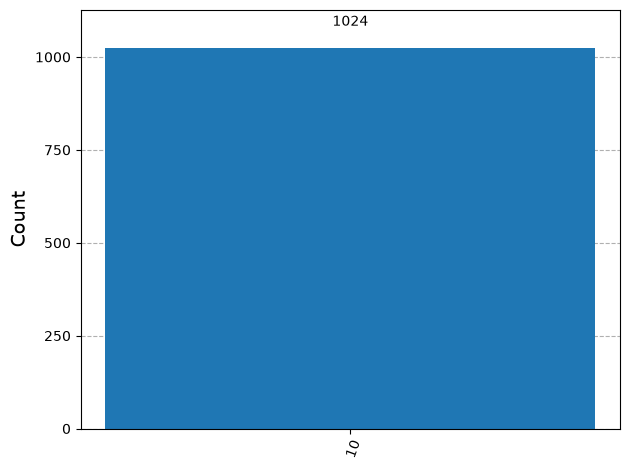

In [39]:
simulator = BasicSimulator()

# Grover with 1 iteration, marking |10>
qc = grover_search("10", iterations=4)

# Compile circuit for simulator
compiled_qc = transpile(qc, simulator)

# Execute 1024 measurements
result = simulator.run(compiled_qc, shots=1024).result()

counts = result.get_counts()

print(counts)
display(plot_histogram(counts))

In [37]:
shots = 1024

for iterations in [1, 2]:
    print(f"\n--- Grover: {iterations} iteration(s) ---")

    for target in ["00", "01", "10", "11"]:
        qc = grover_search(target, iterations)

        compiled = transpile(qc, simulator)
        result = simulator.run(compiled, shots=shots).result()

        counts = result.get_counts()
        probability = counts.get(target, 0) / shots

        print(f"Target |{target}>")
        print(f"  Counts: {counts}")
        print(f"  Success: {probability:.2%}")


--- Grover: 1 iteration(s) ---
Target |00>
  Counts: {'00': 1024}
  Success: 100.00%
Target |01>
  Counts: {'01': 1024}
  Success: 100.00%
Target |10>
  Counts: {'10': 1024}
  Success: 100.00%
Target |11>
  Counts: {'11': 1024}
  Success: 100.00%

--- Grover: 2 iteration(s) ---
Target |00>
  Counts: {'00': 267, '01': 257, '10': 248, '11': 252}
  Success: 26.07%
Target |01>
  Counts: {'10': 267, '11': 268, '00': 251, '01': 238}
  Success: 23.24%
Target |10>
  Counts: {'01': 271, '11': 260, '00': 242, '10': 251}
  Success: 24.51%
Target |11>
  Counts: {'00': 259, '01': 297, '11': 231, '10': 237}
  Success: 22.56%


In [38]:
for iterations in range(12):
    qc = grover_search("10", iterations)
    result = simulator.run(
        transpile(qc, simulator),
        shots=1024
    ).result()

    counts = result.get_counts()
    success = counts.get("10", 0) / 1024

    print(f"{iterations:2d} iterations: {success:.1%}")

 0 iterations: 22.5%
 1 iterations: 100.0%
 2 iterations: 24.9%
 3 iterations: 25.0%
 4 iterations: 100.0%
 5 iterations: 26.0%
 6 iterations: 24.6%
 7 iterations: 100.0%
 8 iterations: 25.8%
 9 iterations: 22.5%
10 iterations: 100.0%
11 iterations: 24.2%
